# Which patterns are conserved, and which differ across planets?

Asteron's joint model linked two views from the same inhabitants. We now add **Borealis's 72 different inhabitants** to Asteron's 80, retaining 90 common RNA features and 60 common protein features within each modality. Samples match across views within a planet, but not across planets.

We will revisit the four independent fits, fit a pooled two-view model, and then fit an explicitly grouped two-view model. A later exploratory fit increases model complexity. At every step, ask which samples and views enter the likelihood, which coordinates are shared, and what preprocessing has changed.

**Predict:** if Borealis has a mean offset and stronger within-planet variation, will pooled and group-centred models answer the same question?

### Read the canonical observations

`course_utils` supplies the saved-data readers, input-preparation helpers, plotting and comparison functions, and `FIT`. `load_experiment()` returns the four AnnData tables as `data[planet][view]`, without generating new data or loading true activities. This notebook will use both planets and both modalities.

In [2]:
from pathlib import Path
import sys, time
HERE = Path.cwd() if Path('course_utils.py').exists() else Path.cwd() / 'notebooks'
sys.path.insert(0, str(HERE))
from course_utils import *
from IPython.display import display
from sklearn.decomposition import PCA
# Observations only. Ground truth is loaded explicitly for later diagnostics.
data = load_experiment()

### Start with visible settings

We import MOFA-FLEX and restrict PyTorch to one CPU thread. In a fresh kernel, the imported `FIT` dictionary starts at seed 42, Gaussian likelihood and base learning rate .02 with the common epoch/stopping controls. The pooled-fit cell below explicitly changes that rate to .001 for the subsequent fits in this notebook. Printing settings is preparation, not model fitting.

In [3]:
import mofaflex as mf
import torch
torch.set_num_threads(1)
print('MOFA-FLEX', mf.__version__)
print('Training settings:', FIT)

Importing the dtw module. When using in academic works please cite:
  T. Giorgino. Computing and Visualizing Dynamic Time Warping Alignments in R: The dtw Package.
  J. Stat. Soft., doi:10.18637/jss.v031.i07.

MOFA-FLEX 0.2.0rc2.dev16+g2710274b7
Training settings: {'device': 'cpu', 'likelihoods': 'Normal', 'seed': 42, 'save_path': False, 'max_epochs': 1200, 'lr': 0.02, 'early_stopper_patience': 250, 'batch_size': 0, 'subset_var': None, 'plot_data_overview': False, 'update_every': -1, 'scale_elbo': True}


/Users/flores/Dropbox/EBI/Teaching/VIB/MOFA_training/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
/Users/flores/Dropbox/EBI/Teaching/VIB/MOFA_training/.venv/lib/python3.12/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.


## Inspect the two populations before modelling them together

We begin with the **four saved observed tables**, not a new fit. `schematic('multigroup')` draws the intended arrangement: different score rows for each planet and one shared weight pattern per view. It is a conceptual diagram, not evidence that fitting has established conservation.

The cell then combines sample metadata, displays disease and batch composition, and verifies matching feature identifiers within each view. Means and variance histograms are calculated directly from `.X`, before model centring or scaling. Distinguish a between-planet mean offset from greater variability within one planet. The inhabitants are different, so these curves compare feature summaries rather than paired sample measurements.

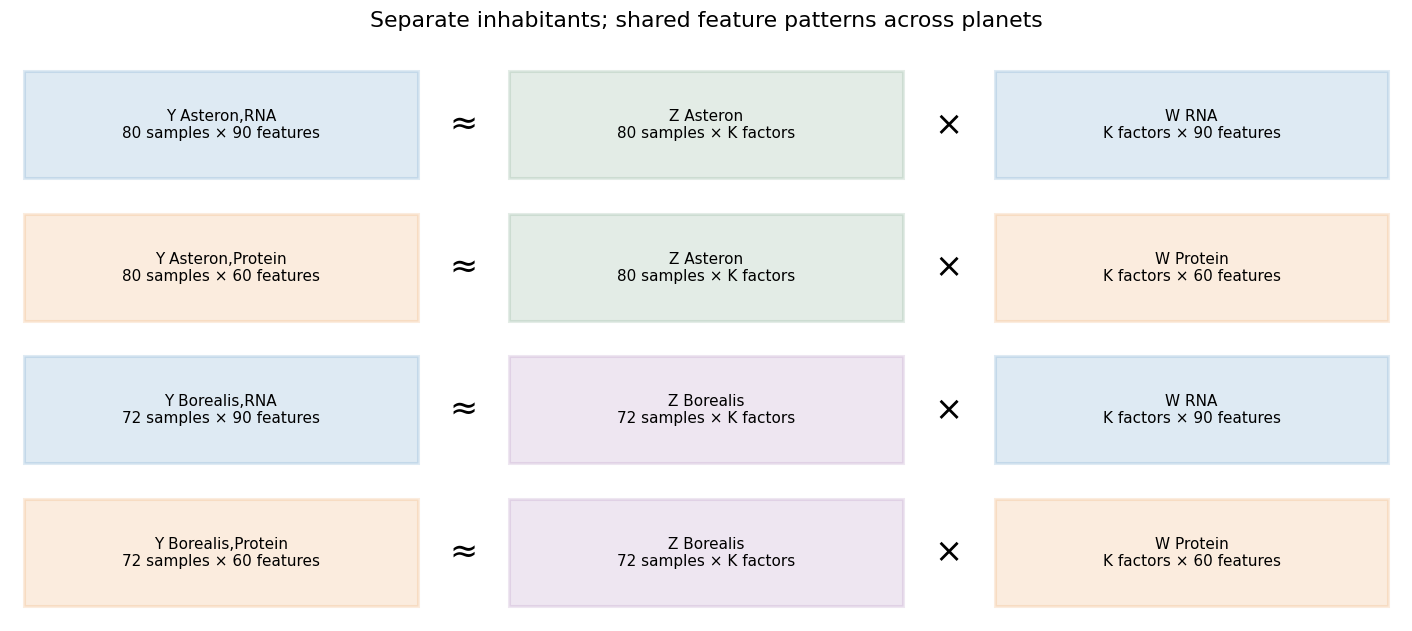

disease,Diseased,Healthy
planet,,
Asteron,40,40
Borealis,48,24


batch,0,1
planet,,
Asteron,36,44
Borealis,36,36


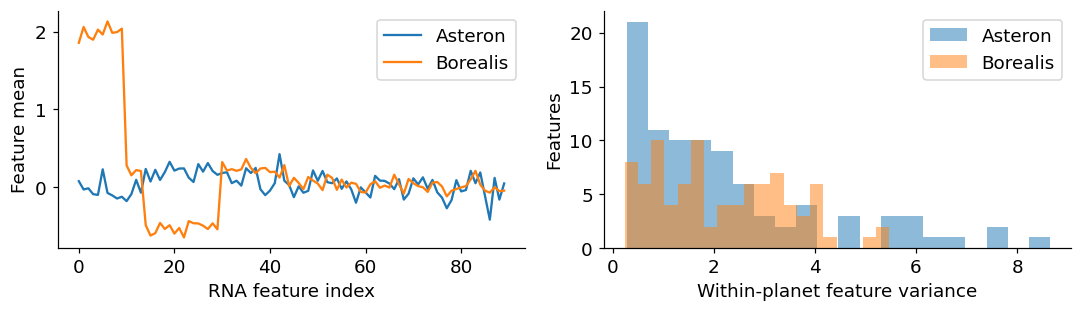

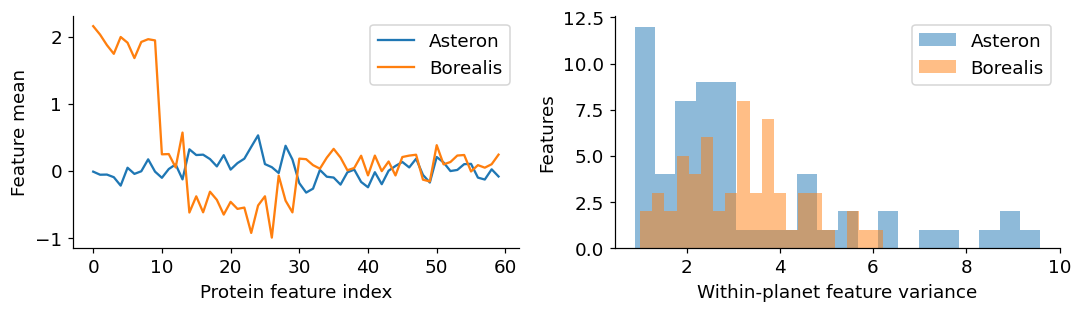

In [4]:
schematic('multigroup')
metadata = pd.concat([data[g]['RNA'].obs for g in SPEC['samples']])
display(pd.crosstab(metadata.planet, metadata.disease), pd.crosstab(metadata.planet, metadata.batch))
for v in SPEC['features']:
    assert data['Asteron'][v].var_names.equals(data['Borealis'][v].var_names)
    fig, axes = plt.subplots(1, 2, figsize=(10, 3))
    for g in SPEC['samples']:
        a = data[g][v]
        axes[0].plot(a.X.mean(0), label=g)
        axes[1].hist(a.X.var(0), bins=20, alpha=.5, label=g)
    axes[0].set(xlabel=f'{v} feature index', ylabel='Feature mean')
    axes[1].set(xlabel='Within-planet feature variance', ylabel='Features')
    axes[0].legend(); axes[1].legend(); fig.tight_layout(); plt.show()

## Revisit the four independent models

We first read the **four six-factor Gaussian, SpikeSlab-weight models fitted independently in notebook 04**. `read_scores(name)` loads their exported score CSVs; the R² CSV stores each model's whole-table reconstruction summary. No model is fitted in this cell.

`disease_association` matches score rows to the relevant planet's metadata, encodes disease status as 0/1 and computes absolute correlations with each local factor. The maximum is a descriptive association, not a shared factor identity or a significance test. These four local coordinate systems are our reference for asking what pooling and grouping change.

In [5]:
rows = []
for g in SPEC['samples']:
    for v in SPEC['features']:
        name = f'independent_{g}_{v}'
        z = read_scores(name)
        r = pd.read_csv(ROOT / 'results' / name / 'r2.csv').R2.iloc[0]
        rows.append(dict(strategy='Independent single table', planet=g, view=v, R2=r,
                         max_disease_correlation=disease_association(z, data[g][v].obs).max()))
display(pd.DataFrame(rows))

,strategy,planet,view,R2,max_disease_correlation
0,Independent single table,Asteron,RNA,0.878830,0.821596
1,Independent single table,Asteron,Protein,0.684611,0.758847
2,Independent single table,Borealis,RNA,0.878355,0.765407
3,Independent single table,Borealis,Protein,0.696079,0.770153


## Fit a pooled multiview model with no explicit groups

We now fit **one six-factor Gaussian model to all 152 inhabitants and both views**, using Normal factor priors, Horseshoe weight priors and PCA initialisation. Horseshoe is another shrinkage prior; this configuration differs from the independent SpikeSlab fits, so comparisons will not isolate pooling alone.

`pooled_views(data)` copies the two planets' tables and concatenates their rows **within each modality**, keeping matching features. Its default `center_within=False` leaves planet means in place. `make_mudata(...)` checks and aligns RNA/protein sample IDs, preserving two feature spaces in one container. Both helpers prepare inputs; inference starts at `pool_model.fit(...)`.

`FIT['lr'] = 0.001` changes the shared settings dictionary inside this notebook. That rate is used for this pooled fit and the subsequent grouped fits. Other settings retain their printed values. Because `.fit` has no `group_by`, the `planet` metadata column remains an annotation: the model uses one 152 × 6 score block and global per-view centring/scaling.

**Predict:** could a pooled direction distinguish planets because of their mean offsets or disease composition, rather than a conserved disease program?

In [6]:
pooled_views_data = pooled_views(data)
mpooled = make_mudata(pooled_views_data)
pool_model = mf.terms.MofaFlex(n_factors=6, factor_prior='Normal',
                               weight_prior='Horseshoe', init_factors='pca')
FIT["lr"] = 0.001
pool_model.fit(mpooled, **FIT)

z_pool = next(iter(pool_model.get_factors().values()))

INFO	Initializing factors using 'pca' method...


INFO 	 Guessed max_plate_nesting = 2


### Inspect the pooled model's variance summary

`mf.pl.variance_explained(pool_model)` displays reconstruction summaries from the **six-factor pooled RNA–protein fit over all 152 inhabitants**. It does not create groups or refit anything. A factor explaining pooled variation may reflect differences between planets as well as variation among inhabitants within a planet.

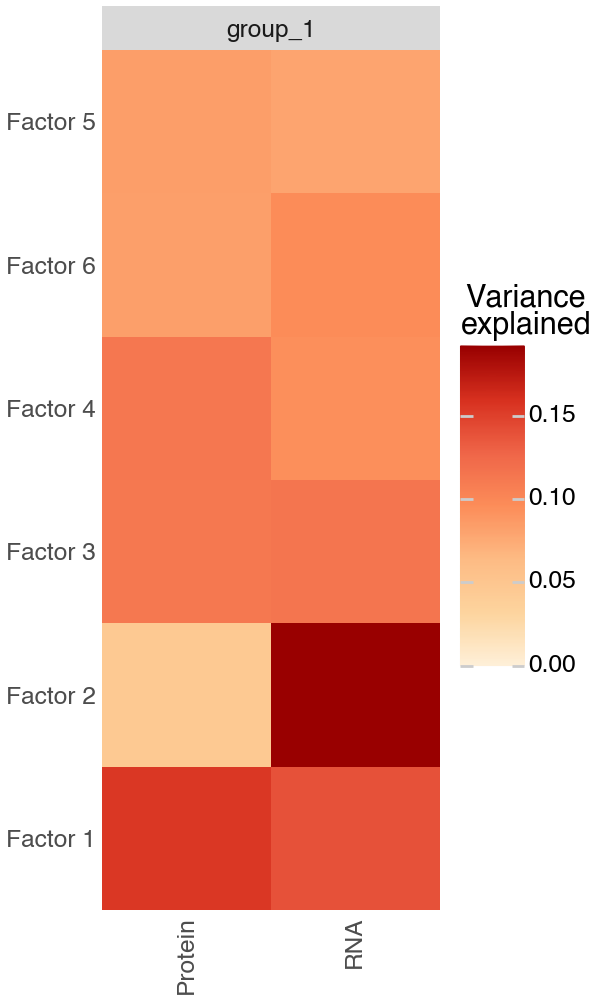

In [7]:
mf.pl.variance_explained(pool_model)


### Ask whether pooled coordinates separate the planets

`score_plot` draws the first two score columns from the **pooled six-factor model**, colouring inhabitants by planet after fitting. `crosscorr` matches score rows to the 0/1 Borealis indicator and measures each factor's association with that annotation; `heatmap` displays the absolute correlations. Such an association does not reveal whether its source is biology, composition or technical offsets.

`export_fit(pool_model, 'pooled')` saves scores, per-view weights, total R² and loss to `results/pooled/`. It neither refits the model nor changes the interpretation of the metadata into explicit groups.

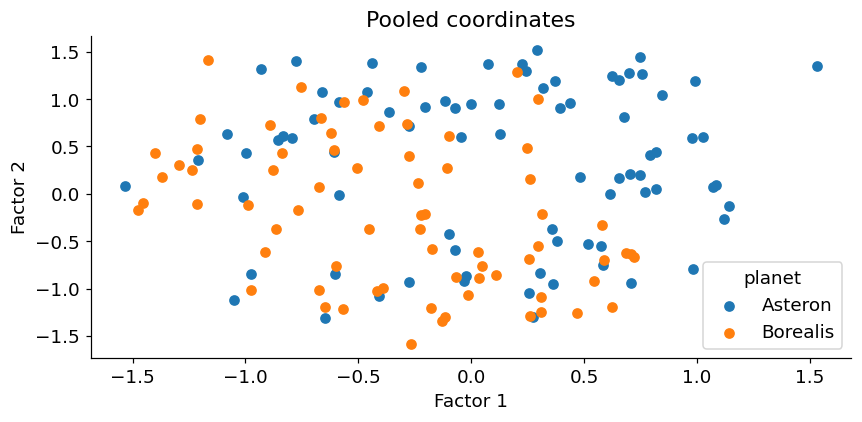

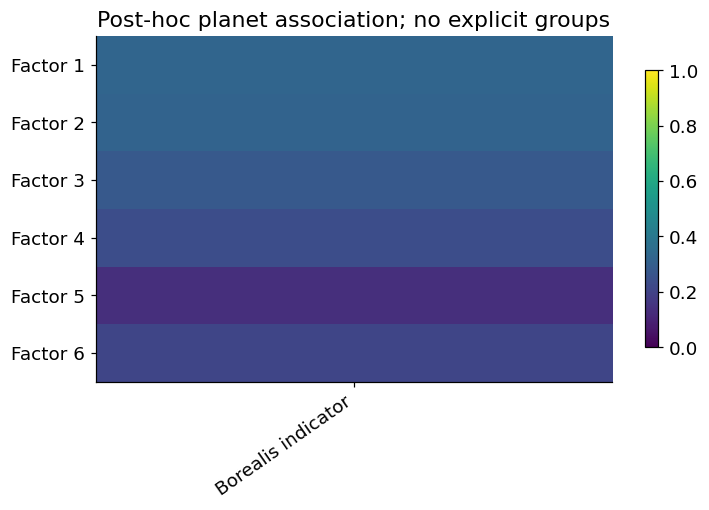

In [8]:
score_plot(z_pool, metadata, color='planet', title='Pooled coordinates')
indicator = metadata.planet.eq('Borealis').astype(float).to_frame('Borealis indicator')
heatmap(crosscorr(z_pool, indicator).abs(), 'Post-hoc planet association; no explicit groups', vmin=0, vmax=1)
export_fit(pool_model, 'pooled')

## Fit explicit groups while sharing feature weights

We next fit **a six-factor Gaussian multiview model with Asteron and Borealis as explicit groups**, using Normal factor priors, SpikeSlab weights and PCA initialisation. The base learning rate remains .001 after the earlier `FIT` assignment. The pooled model used Horseshoe weights, so the comparison changes prior as well as grouping.

$$\widetilde Y^{(m,g)}_{N_g\times D_m}\approx Z^{(g)}_{N_g\times6}W^{(m)}_{6\times D_m}.$$

`group_by='planet'` tells MOFA-FLEX to use separate sample-factor tables for Asteron (80 × 6) and Borealis (72 × 6), with one shared weight matrix per view (6 × 90 RNA and 6 × 60 protein in this equation). We pass the same MuData object as before; the model's interpretation of its metadata changes because we now specify the grouping argument.

The Gaussian likelihood centres features and applies one scalar scale **within each group/view**, unlike global pooled preprocessing. Its residual dispersions are view/feature-specific and shared across groups in this implementation. Normal factor priors here do not add MOFA2-style group-specific ARD. Group means and scales are preprocessing quantities, not planet-specific loading matrices.

We first display `mpooled.obs` so we can inspect the actual `planet` column that will define groups. **Predict:** should Borealis's additive intercept remain in group-centred scores? Should a laboratory effect that varies within both planets remain?

In [9]:
mpooled.obs

,planet,disease,batch
Asteron_000,Asteron,Healthy,0
Asteron_001,Asteron,Healthy,0
Asteron_002,Asteron,Diseased,1
Asteron_003,Asteron,Healthy,0
Asteron_004,Asteron,Diseased,0
...,...,...,...
Borealis_067,Borealis,Healthy,1
Borealis_068,Borealis,Healthy,1
Borealis_069,Borealis,Diseased,1
Borealis_070,Borealis,Diseased,0


### Run the six-factor grouped fit

We now construct and fit the **two-group, two-view Gaussian model with six factors, Normal factor priors and SpikeSlab weights**. `group_by='planet'` is the operative change that makes groups explicit. `**FIT` includes the .001 learning rate assigned earlier. The feature sets match within each view across groups; the samples remain different people.

In [10]:
group_model = mf.terms.MofaFlex(n_factors=6, factor_prior='Normal',
                                weight_prior='SpikeSlab', init_factors='pca')

group_model.fit(mpooled, group_by='planet', **FIT)

INFO	Initializing factors using 'pca' method...


INFO 	 Guessed max_plate_nesting = 2


### Keep the grouped scores available for later comparisons

`get_factors()` returns the **six-factor grouped model's** score tables keyed by planet; `z_groups` retains those separate 80 × 6 and 72 × 6 tables. `export_fit(..., 'grouped')` writes their scores, shared per-view weights, total R² and loss to `results/grouped/`. Extracting and saving these summaries performs no new inference. This saved `z_groups` variable will still refer to this fit even after the later exploratory model is constructed.

In [11]:
z_groups = group_model.get_factors()
export_fit(group_model, 'grouped')

### Read reconstruction by group and view

This variance plot belongs to the **six-factor grouped SpikeSlab model**. Group/view summaries describe reconstruction after that model's within-group preprocessing. They are not the pooled model's global-baseline R², and high reconstruction does not establish a conserved biological mechanism.

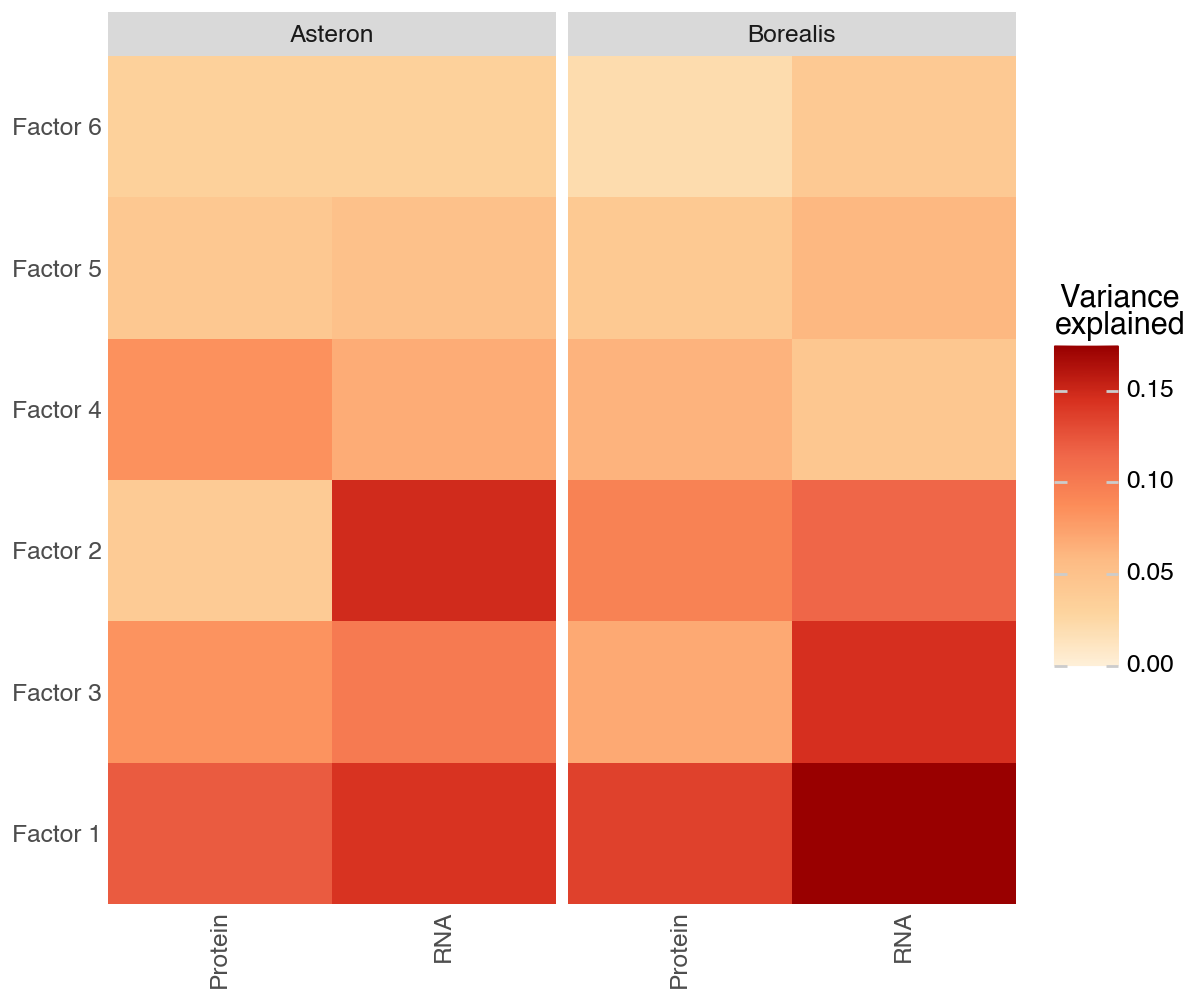

In [12]:
mf.pl.variance_explained(group_model)


### Look at the shared molecular patterns

`get_weights()` returns one feature × six table for RNA and one for protein from the **six-factor grouped model**. There is no separate Asteron and Borealis weight table here: sharing within a view is part of the model. `weights_plot` selects 18 strong features per supplied table and draws their signed weights. These selected panels illustrate the shared patterns but omit the remaining features.

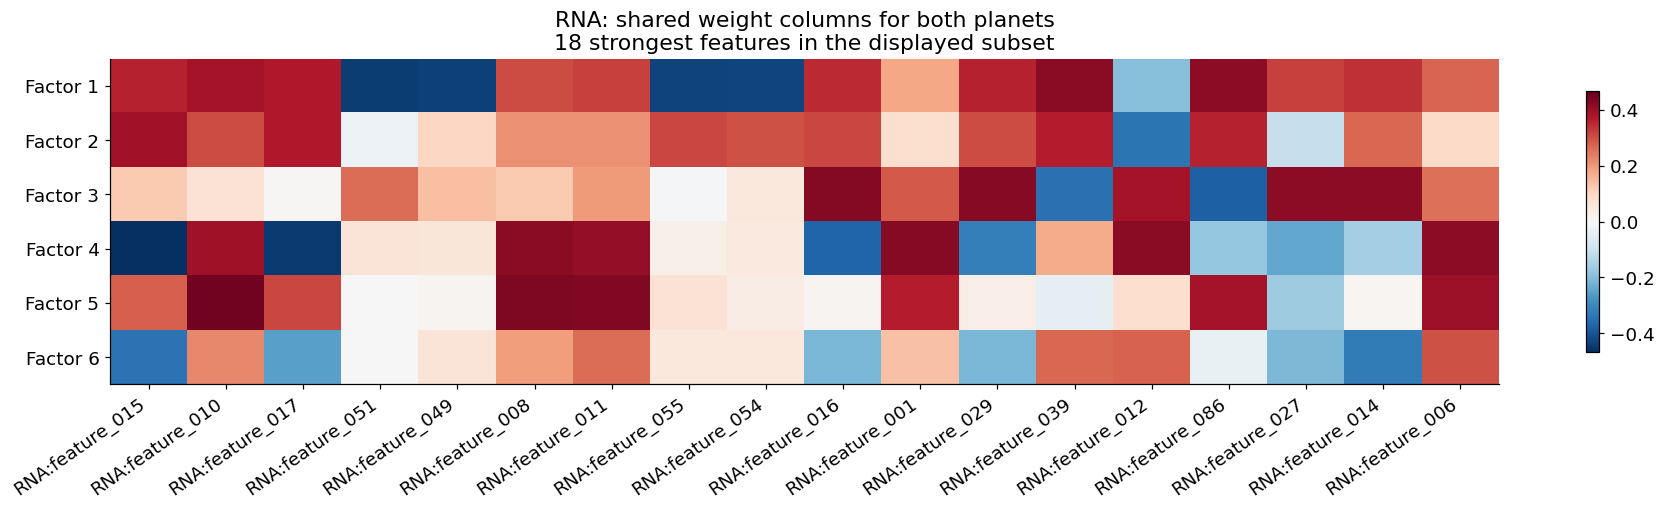

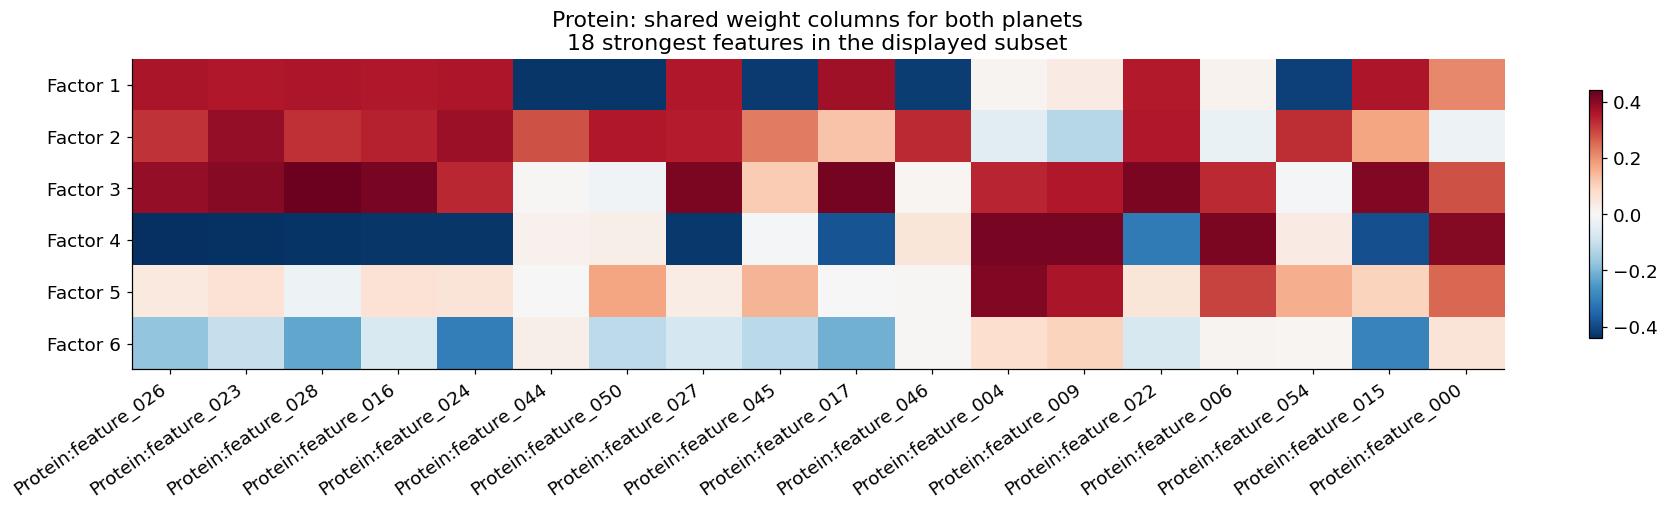

In [13]:
for v, w in group_model.get_weights().items():
    weights_plot(w, f'{v}: shared weight columns for both planets')

## Interpret the grouped sample factors

We now inspect the **six-factor grouped SpikeSlab model**, whose score tables are stored in `z_groups`. Each planet has different score rows but the same factor columns and shared per-view weights. This permits within-model comparisons of activity patterns, without pairing inhabitants between planets.

`load_truth()` reads the teacher activities only for evaluation. For each planet, `crosscorr` matches that planet's inhabitant IDs and computes correlations between learned and true score columns. `.abs()` resolves signs, and `heatmap` displays the table. Correlations still depend on rotations and mixtures; factor numbers are not the true process names.

**Predict:** where should the larger Borealis planet-response variability become visible? Remember that group centring removes raw mean offsets and group/view scaling changes units. Score spread is therefore not automatically the original biological effect size.

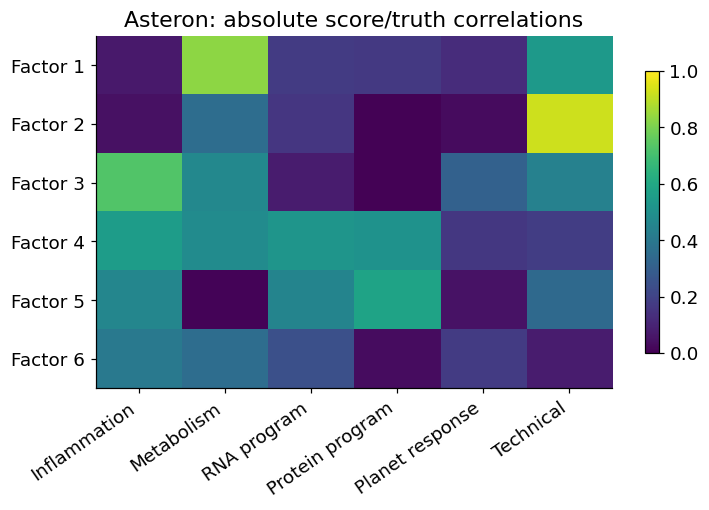

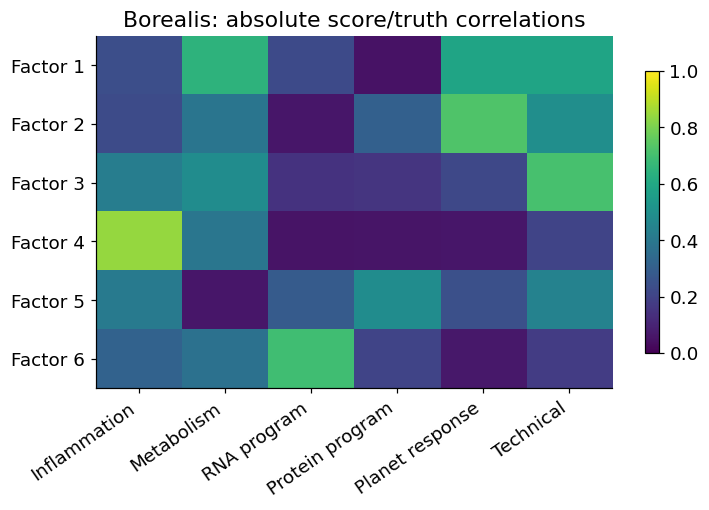

In [14]:
teacher = load_truth()
for g, z in z_groups.items():
    heatmap(crosscorr(z, teacher['scores'][g]).abs(), f'{g}: absolute score/truth correlations', vmin=0, vmax=1)


### View Asteron's inhabitants on two grouped-model axes

We select `Factor 3` and `Factor 4` from **Asteron's six-factor grouped scores**, rather than fitting a new two-factor model. `score_plot` draws the first two supplied columns and aligns metadata by inhabitant ID before adding disease colours. The code's generic title says “Pooled coordinates”; this panel actually uses the **grouped Asteron fit**. These factor numbers are positions in the fitted representation, not names assigned to true processes.

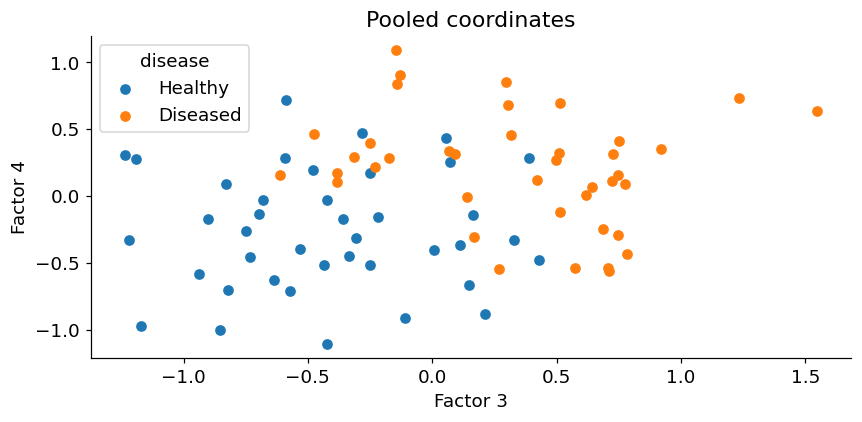

In [15]:
score_plot((z_groups["Asteron"])[["Factor 3", "Factor 4"]], metadata, color='disease', title='Pooled coordinates')

### Use the same grouped-model columns for Borealis

This panel uses `Factor 3` and `Factor 4` from **Borealis's six-factor grouped scores**, with different inhabitants and the same shared feature-weight columns as Asteron. Again, the existing title says “Pooled coordinates”, but the supplied scores are grouped. Compare distributions and disease associations rather than pairing points across planets; remember the different preprocessing scales.

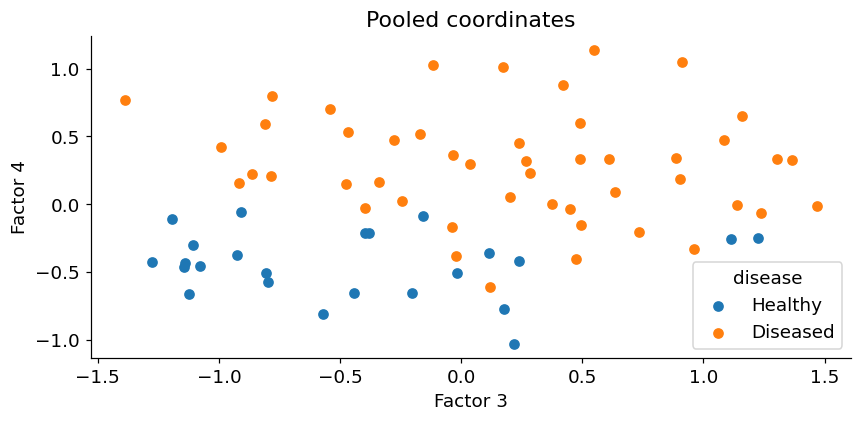

In [16]:
score_plot((z_groups["Borealis"])[["Factor 3", "Factor 4"]], metadata, color='disease', title='Pooled coordinates')

## Compare reconstruction using a common within-planet baseline

We now compare predictions from the **four independent models, six-factor pooled Horseshoe model and six-factor grouped SpikeSlab model**. Their API R² summaries use different populations and mean baselines, so we should not rank a pooled 152-inhabitant R² directly against a within-planet R².

The next cell makes the reconstruction arithmetic visible. For the independent models it reads both exported scores and weights. For pooled and grouped models it uses the already fitted scores and weights in memory. It multiplies scores by weights, then restores the mean and single-RMS scale appropriate to each fit to return predictions to the original abundance units. For each planet–view table, all strategies are evaluated against that table's **same feature-mean baseline**.

Read each table entry as training reconstruction of the measured RNA or protein, not recovery of a true activity. Negative values are retained in this direct calculation. Priors and preprocessing still differ between strategies; using a common denominator does not turn this into a grouping-only experiment.

In [17]:
reconstruction_rows = []
for g in SPEC['samples']:
    for v in SPEC['features']:
        a = data[g][v]; y = a.X; ids = a.obs_names
        base = ROOT / 'results' / f'independent_{g}_{v}'
        zi = read_scores(f'independent_{g}_{v}').loc[ids]
        wi = pd.read_csv(base / f'weights_{v}.csv', index_col=0)
        predictions = {'Independent': (zi.to_numpy() @ wi.to_numpy().T) * np.sqrt(np.mean((y-y.mean(0))**2)) + y.mean(0)}
        for label, zz, ww, reference in [
            ('Pooled', z_pool.loc[ids], pool_model.get_weights()[v], pooled_views_data[v].X),
            ('Grouped', z_groups[g].loc[ids], group_model.get_weights()[v], y)]:
            scale = np.sqrt(np.mean((reference-reference.mean(0))**2))
            predictions[label] = (zz.to_numpy() @ ww.to_numpy().T)*scale + reference.mean(0)
        for label, pred in predictions.items():
            r2 = 1-np.sum((y-pred)**2)/np.sum((y-y.mean(0))**2)
            reconstruction_rows.append(dict(planet=g, view=v, strategy=label, within_planet_R2=r2))
display(pd.DataFrame(reconstruction_rows).pivot(index=['planet','view'], columns='strategy', values='within_planet_R2').round(3))

strategy          Grouped  Independent  Pooled
planet   view                                 
Asteron  Protein    0.372        0.685   0.539
         RNA        0.491        0.879   0.657
Borealis Protein    0.411        0.696   0.568
         RNA        0.537        0.878   0.672

### Compare the grouped API summary with our direct calculation

`group_model.get_r2(type='total')` returns whole-model reconstruction R² by group/view for the **six-factor grouped SpikeSlab model**. It performs no new fit. Its Gaussian API can clip negative values to zero; the preceding direct common-baseline calculation retained negatives. Neither table measures true-score recovery.

In [18]:
group_model.get_r2(type='total')

,group,view,R2
0,Asteron,RNA,0.490754
1,Asteron,Protein,0.372130
2,Borealis,RNA,0.537209
3,Borealis,Protein,0.411063


## Explore a larger grouped model

We now fit **a new 15-factor Gaussian model to both planets and both views**, using explicit planet groups, Normal factor priors, Horseshoe weights, PCA initialisation and the current .001 base learning rate. This changes factor count and weight prior relative to the earlier six-factor grouped fit. It is an exploratory comparison, not a controlled test of factor count alone.

The assignment replaces the object called `group_model`. It does **not** replace `z_groups`, recompute the earlier reconstruction table, or overwrite the earlier exported grouped summaries. Those still describe the six-factor SpikeSlab fit. More factors can describe more training variation, including noise; they do not imply 15 biological programs.

In [19]:
group_model = mf.terms.MofaFlex(n_factors=15, factor_prior='Normal',
                                weight_prior='Horseshoe', init_factors='pca')

group_model.fit(mpooled, group_by='planet', **FIT)

INFO	Initializing factors using 'pca' method...


INFO 	 Guessed max_plate_nesting = 2


### Inspect reconstruction from the new 15-factor model

This `get_r2(type='total')` call now refers to the **15-factor grouped Horseshoe fit**, because `group_model` was reassigned. Compare it with the preceding six-factor model's summary as an exploratory training result. A reconstruction gain alone would not justify the larger model or attribute that gain separately to factor count and prior.

In [20]:
group_model.get_r2(type='total')

,group,view,R2
0,Asteron,RNA,0.735615
1,Asteron,Protein,0.616419
2,Borealis,RNA,0.734111
3,Borealis,Protein,0.632760


## Return to the original strategy comparison

The exploratory fit has changed `group_model`, so pause to identify the objects used below. **`z_groups` still contains the six-factor grouped SpikeSlab scores saved earlier**, and `z_pool` still contains the six-factor pooled Horseshoe scores. The following comparisons use those original representations and the four independent fits; they do not use the new 15-factor model.

`crosscorr` matches the concatenated six-factor grouped scores to laboratory-batch labels by inhabitant ID. Its heatmap asks whether within-planet technical variation remains associated with the learned factors. Group membership does not itself remove such variation.

For each planet, `truth_projection` centres matching rows and uses a least-squares combination of each representation's score columns to predict the true activities. These are training activity-recovery R² values, not measured-abundance reconstruction R², and the diagnostic regression does not alter the omics fits. `read_scores` brings back the independent score CSVs without retraining those models.

**Predict:** can sharing feature weights across planets distinguish technical from biological variation without additional design information?

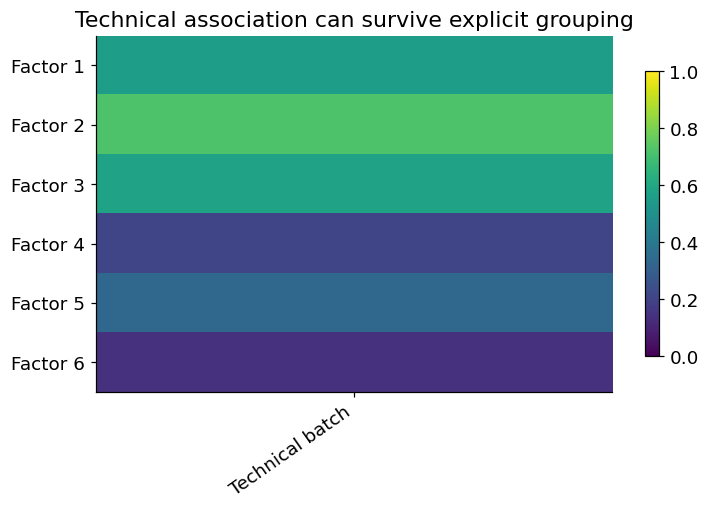

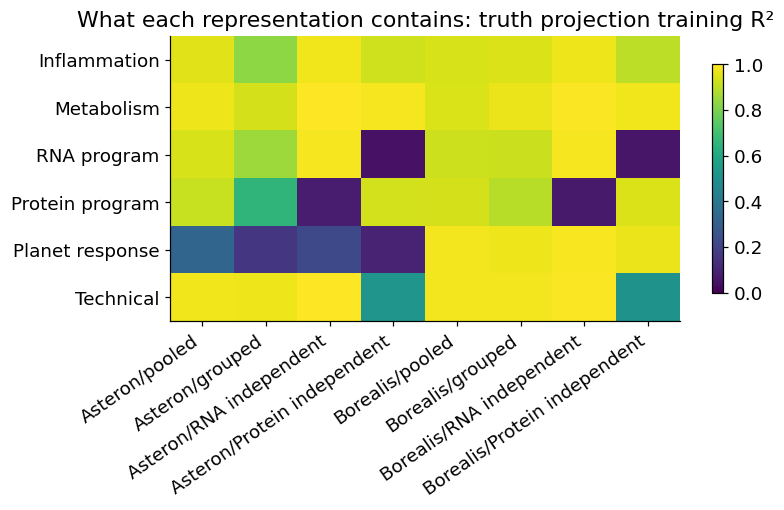

In [21]:
batch = metadata.batch.astype(float).to_frame('Technical batch')
heatmap(crosscorr(pd.concat(z_groups.values()), batch).abs(),
        'Technical association can survive explicit grouping', vmin=0, vmax=1)
recovery = {}
for g in SPEC['samples']:
    recovery[f'{g}/pooled'] = truth_projection(z_pool.loc[data[g]['RNA'].obs_names], teacher['scores'][g])
    recovery[f'{g}/grouped'] = truth_projection(z_groups[g], teacher['scores'][g])
    for v in SPEC['features']:
        recovery[f'{g}/{v} independent'] = truth_projection(read_scores(f'independent_{g}_{v}'), teacher['scores'][g])
heatmap(pd.DataFrame(recovery), 'What each representation contains: truth projection training R²', vmin=0, vmax=1)

## What can we conclude about sharing across planets?

We have compared **independent table models, a pooled two-view model and an explicitly grouped two-view model**, then explored a larger grouped model. Independent fits revealed local structure but required careful correspondence checks. The multiview model shared sample coordinates across modalities; the multigroup model used separate inhabitants' scores with common feature patterns across planets.

Shared weights are a modelling assumption, not independent proof that biology is conserved. Different priors, normalisation, cohort composition and technical effects all influence these comparisons. Grouping does not automatically correct batch effects or recover mean shifts removed by centring. A weak Asteron process remains harder to establish than the stronger Borealis version.

Looking back at the current outputs, name one conclusion each strategy supports and one it cannot support. When might separate analysis be preferable? What additional measurements or study design would help test conservation beyond our shared-loading simulation?

For optional exploration, pool after within-planet centring using `pooled_views(data, center_within=True)`, and ask how removing offsets changes the pooled representation before attributing differences to explicit grouping.